### KDD · Fase 4: Minería de datos

Entrenamiento de un Random Forest para clasificar la especie. El grupo de prueba no se usa en esta fase.

- **Entrada:** `kdd/data/processed/train_transformed.csv`
- **Salidas:**
  - `kdd/models/random_forest.joblib`: modelo final
  - `kdd/models/baseline.joblib`: modelo de referencia
  - `kdd/data/processed/cv_results.csv`: resultados de la validación cruzada
  - `kdd/figures/mining_cv_results.png`: desempeño según los hiperparámetros

#### Librerías

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

#### Semilla

In [2]:
# Semilla para reproducibilidad. Puede modificarse o eliminarse.
SEED = 1

#### Rutas

Relativas a la carpeta del notebook.

In [3]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
for folder in [MODELS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [4]:
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [5]:
train = pd.read_csv(PROCESSED_DIR / "train_transformed.csv")

TARGET = "species"
FEATURES = [c for c in train.columns if c not in ["row_id", TARGET]]

X_train = train[FEATURES]
y_train = train[TARGET]

print(f"Registros: {len(X_train)} | Variables: {len(FEATURES)}")
print(FEATURES)

Registros: 273 | Variables: 11
['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'culmen_ratio', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_FEMALE', 'sex_MALE', 'sex_UNKNOWN']


#### Validación cruzada estratificada de 5 pliegues

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

#### Modelo de referencia

Predice siempre la especie más frecuente.

In [7]:
baseline = DummyClassifier(strategy="most_frequent")
baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=["f1_macro", "accuracy"])

print(f"F1 macro: {baseline_cv['test_f1_macro'].mean():.3f}")
print(f"Exactitud: {baseline_cv['test_accuracy'].mean():.3f}")

F1 macro: 0.205
Exactitud: 0.443


#### Búsqueda de hiperparámetros

Se elige la combinación con mayor F1 macro.

In [8]:
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 3, 6],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.5],
}

search = GridSearchCV(
    RandomForestClassifier(oob_score=True, random_state=SEED, n_jobs=-1),
    param_grid=param_grid,
    scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print(f"Mejores hiperparámetros: {search.best_params_}")
print(f"F1 macro: {search.best_score_:.4f}")

Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
F1 macro: 0.9907


#### Resultados de la validación cruzada

In [9]:
res = pd.DataFrame(search.cv_results_)

cv_results = pd.DataFrame({
    "modelo": "random_forest",
    "n_estimators": res["param_n_estimators"],
    "max_depth": res["param_max_depth"].astype(object).where(res["param_max_depth"].notna(), "None"),
    "min_samples_leaf": res["param_min_samples_leaf"],
    "max_features": res["param_max_features"],
    "f1_macro_mean": res["mean_test_f1_macro"],
    "f1_macro_std": res["std_test_f1_macro"],
    "accuracy_mean": res["mean_test_accuracy"],
    "accuracy_std": res["std_test_accuracy"],
    "rank": res["rank_test_f1_macro"],
})

baseline_row = pd.DataFrame([{
    "modelo": "baseline_most_frequent",
    "f1_macro_mean": baseline_cv["test_f1_macro"].mean(),
    "f1_macro_std": baseline_cv["test_f1_macro"].std(),
    "accuracy_mean": baseline_cv["test_accuracy"].mean(),
    "accuracy_std": baseline_cv["test_accuracy"].std(),
}])

cv_results = pd.concat([baseline_row, cv_results.sort_values("rank")], ignore_index=True).round(4)
cv_results = cv_results[[
    "modelo", "n_estimators", "max_depth", "min_samples_leaf", "max_features",
    "f1_macro_mean", "f1_macro_std", "accuracy_mean", "accuracy_std", "rank",
]]
for col in ["n_estimators", "min_samples_leaf", "rank"]:
    cv_results[col] = cv_results[col].astype("Int64")
cv_results.head(11)

,modelo,n_estimators,max_depth,min_samples_leaf,max_features,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,rank
0,baseline_most_frequent,<NA>,NaN,<NA>,NaN,0.2047,0.0033,0.4433,0.0103,<NA>
1,random_forest,200,None,1,sqrt,0.9907,0.0187,0.9927,0.0145,1
2,random_forest,500,None,1,sqrt,0.9907,0.0187,0.9927,0.0145,1
3,random_forest,500,6,1,sqrt,0.9907,0.0187,0.9927,0.0145,1
4,random_forest,200,6,1,sqrt,0.9907,0.0187,0.9927,0.0145,1
5,random_forest,500,6,1,0.5,0.9864,0.0272,0.9891,0.0218,5
6,random_forest,200,6,1,0.5,0.9864,0.0272,0.9891,0.0218,5
7,random_forest,200,None,1,0.5,0.9864,0.0272,0.9891,0.0218,5
8,random_forest,500,None,1,0.5,0.9864,0.0272,0.9891,0.0218,5
9,random_forest,200,3,1,0.5,0.9864,0.0272,0.9891,0.0218,5


#### Desempeño según los hiperparámetros

Mejor combinación de `n_estimators` y `max_features` para cada par de `max_depth` y `min_samples_leaf`. Las barras indican la desviación estándar entre pliegues.

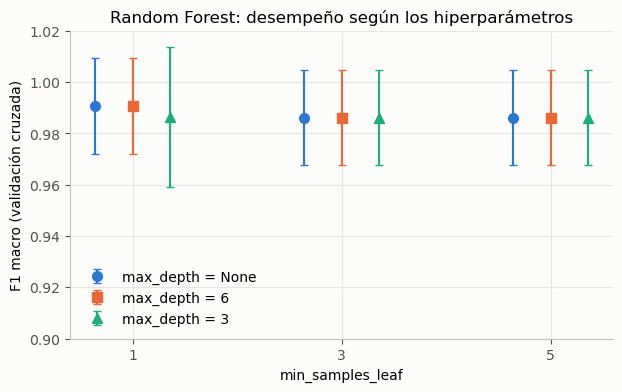

,max_depth,min_samples_leaf,f1_macro_mean,f1_macro_std
0,None,1,0.9907,0.0187
1,6,1,0.9907,0.0187
2,3,1,0.9864,0.0272
3,3,3,0.9861,0.0186
4,None,5,0.9861,0.0186
5,None,3,0.9861,0.0186
6,3,5,0.9861,0.0186
7,6,3,0.9861,0.0186
8,6,5,0.9861,0.0186


In [10]:
rf_rows = cv_results[cv_results["modelo"] == "random_forest"]
best_by_pair = (
    rf_rows.sort_values("rank")
    .groupby(["max_depth", "min_samples_leaf"], sort=False)
    .first()[["f1_macro_mean", "f1_macro_std"]]
    .reset_index()
)

depths = ["None", 6, 3]
colors = {"None": "#2a78d6", 6: "#eb6834", 3: "#1baf7a"}
markers = {"None": "o", 6: "s", 3: "^"}
leaves = [1, 3, 5]

fig, ax = plt.subplots(figsize=(7, 4))
for k, depth in enumerate(depths):
    rows = best_by_pair[best_by_pair["max_depth"] == depth].set_index("min_samples_leaf").loc[leaves]
    x = [i + (k - 1) * 0.18 for i in range(len(leaves))]
    ax.errorbar(x, rows["f1_macro_mean"], yerr=rows["f1_macro_std"], fmt=markers[depth],
                color=colors[depth], markersize=7, capsize=3, label=f"max_depth = {depth}")
ax.set_xticks(range(len(leaves)), leaves)
ax.set_ylim(0.9, 1.02)
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("F1 macro (validación cruzada)")
ax.set_title("Random Forest: desempeño según los hiperparámetros")
ax.legend(loc="lower left")
fig.savefig(FIGURES_DIR / "mining_cv_results.png")
plt.show()

best_by_pair.round(4)

#### Modelo final

In [11]:
final_model = search.best_estimator_
baseline.fit(X_train, y_train)

print(final_model)
print(f"Exactitud fuera de bolsa (OOB): {final_model.oob_score_:.4f}")

RandomForestClassifier(n_estimators=200, n_jobs=-1, oob_score=True,
                       random_state=1)
Exactitud fuera de bolsa (OOB): 0.9890


#### Guardado de resultados

In [12]:
cv_results.to_csv(PROCESSED_DIR / "cv_results.csv", index=False)
joblib.dump(final_model, MODELS_DIR / "random_forest.joblib")
joblib.dump(baseline, MODELS_DIR / "baseline.joblib")

for path in [
    PROCESSED_DIR / "cv_results.csv",
    MODELS_DIR / "random_forest.joblib",
    MODELS_DIR / "baseline.joblib",
    FIGURES_DIR / "mining_cv_results.png",
]:
    print(f"Guardado: {path}")

Guardado: ..\data\processed\cv_results.csv
Guardado: ..\models\random_forest.joblib
Guardado: ..\models\baseline.joblib
Guardado: ..\figures\mining_cv_results.png
